In [1]:
import pandas as pd
import numpy as np

clients = pd.read_csv("clients.csv")
properties = pd.read_csv("properties.csv")

In [2]:
clients.head()

,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
0,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,Yes,Website
1,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,No,Website
2,C0003,Individual,Kale,Gay,04-07-1959,M,USA,California,Home,4,Yes,Agency
3,C0004,Individual,Russell,Gross,11/25/1959,M,USA,California,Home,5,No,Website
4,C0005,Company,Marleez,Co,2/28/1976,M,USA,California,Investment,5,No,Website


In [3]:
properties.head()

,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref
0,1012,1,01-01-2024,Apartment,12,1160.36,"$300,385.62",Sold,C0027
1,1015,1,01-01-2024,Apartment,15,782.25,"$208,930.81",Sold,C0097
2,1021,1,01-01-2024,Apartment,21,756.21,"$218,585.92",Sold,C0113
3,1030,1,01-01-2024,Apartment,30,743.09,"$246,172.68",Sold,C0141
4,2016,2,01-01-2024,Apartment,16,701.66,"$212,265.67",Sold,C0146


In [4]:
print("clients:", clients.shape)
print("properties:", properties.shape)

clients: (2000, 12)
properties: (10000, 9)


In [5]:
clients.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   client_id            2000 non-null   str  
 1   client_type          2000 non-null   str  
 2   first_name           2000 non-null   str  
 3   last_name            2000 non-null   str  
 4   date_of_birth        2000 non-null   str  
 5   gender               2000 non-null   str  
 6   country              2000 non-null   str  
 7   region               2000 non-null   str  
 8   acquisition_purpose  2000 non-null   str  
 9   satisfaction_score   2000 non-null   int64
 10  loan_applied         2000 non-null   str  
 11  referral_channel     2000 non-null   str  
dtypes: int64(1), str(11)
memory usage: 312.6 KB


In [6]:
print("duplicate rows:", clients.duplicated().sum())
print("duplicate client_ids:", clients["client_id"].duplicated().sum())

duplicate rows: 0
duplicate client_ids: 0


In [7]:
clients.isnull().sum()

client_id              0
client_type            0
first_name             0
last_name              0
date_of_birth          0
gender                 0
country                0
region                 0
acquisition_purpose    0
satisfaction_score     0
loan_applied           0
referral_channel       0
dtype: int64

In [8]:
for col in ["client_type", "gender", "country", "region", "acquisition_purpose",
            "loan_applied", "referral_channel", "satisfaction_score"]:
    print(clients[col].value_counts(dropna=False))
    print()

client_type
Individual    1897
Company        103
Name: count, dtype: int64

gender
M    1012
F     988
Name: count, dtype: int64

country
USA          1538
UK             95
Canada         85
Germany        56
France         53
Belgium        43
Mexico         40
Australia      39
Russia         36
Denmark        15
Name: count, dtype: int64

region
California                633
Nevada                    143
Colorado                  118
Arizona                   108
Oregon                     96
Utah                       87
Washington                 73
Virginia                   65
Texas                      56
Florida                    50
New York                   49
Georgia                    34
England                    29
Alberta                    27
Scotland                   25
Northern Ireland           24
Ohio                       24
British Columbia           20
Wales                      17
Hamburg                    16
Flanders                   16
Brittany         

In [9]:
clients["date_of_birth"].sample(15, random_state=1)

674     12/23/1969
1699    11-04-1943
1282    11-08-1945
1315    05-09-1993
1210    07-10-1996
1636    02-11-1969
613     01-07-1972
447     06-10-1980
1131     1/21/1982
808      2/16/1967
1496     1/13/1940
1468     5/17/1970
1682    11/19/1999
1149    11-08-1992
442      6/22/1950
Name: date_of_birth, dtype: str

In [10]:
properties.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   listing_id        10000 non-null  int64  
 1   tower_number      10000 non-null  int64  
 2   transaction_date  10000 non-null  str    
 3   unit_category     10000 non-null  str    
 4   unit_number       10000 non-null  int64  
 5   floor_area_sqft   10000 non-null  float64
 6   sale_price        10000 non-null  str    
 7   listing_status    10000 non-null  str    
 8   client_ref        7305 non-null   str    
dtypes: float64(1), int64(3), str(5)
memory usage: 1.1 MB


In [11]:
print(properties["listing_status"].value_counts(dropna=False))
print(properties["unit_category"].value_counts(dropna=False))
print("missing client_ref:", properties["client_ref"].isnull().sum())

listing_status
Sold         7305
Available    2695
Name: count, dtype: int64
unit_category
Apartment    8547
Office       1453
Name: count, dtype: int64
missing client_ref: 2695


In [12]:
print("clients with purchases:", clients["client_id"].isin(properties["client_ref"]).sum())
print("client_refs not found in clients:", (~properties["client_ref"].dropna().isin(clients["client_id"])).sum())

clients with purchases: 2000
client_refs not found in clients: 0


In [13]:
df = clients.drop(columns=["first_name", "last_name"]).copy()
df["birth_year"] = df["date_of_birth"].str[-4:].astype(int)
df["age"] = 2024 - df["birth_year"]
df[["date_of_birth", "birth_year", "age"]].head()

,date_of_birth,birth_year,age
0,05-11-1968,1968,56
1,11/26/1962,1962,62
2,04-07-1959,1959,65
3,11/25/1959,1959,65
4,2/28/1976,1976,48


In [14]:
df["age"].describe()

count    2000.000000
mean       54.099000
std        17.343719
min        24.000000
25%        39.000000
50%        55.000000
75%        69.000000
max        93.000000
Name: age, dtype: float64

In [15]:
props = properties.copy()
props["sale_price"] = (props["sale_price"]
                       .str.replace("$", "", regex=False)
                       .str.replace(",", "", regex=False)
                       .astype(float))
print(props["sale_price"].describe())
print(props["transaction_date"].str[-4:].value_counts())

count     10000.000000
mean     344374.678683
std      131563.099417
min       97402.800000
25%      232173.642500
50%      330680.845000
75%      448852.575000
max      736652.270000
Name: sale_price, dtype: float64
transaction_date
2024    6014
2025    3986
Name: count, dtype: int64


In [16]:
sold = props[props["listing_status"] == "Sold"].copy()
print(len(sold), "sold rows;", sold["client_ref"].isnull().sum(), "without a client")

7305 sold rows; 0 without a client


In [17]:
spend = sold.groupby("client_ref").agg(
    units_bought=("listing_id", "count"),
    total_spend=("sale_price", "sum"),
    avg_price=("sale_price", "mean"),
    avg_area_sqft=("floor_area_sqft", "mean"),
    office_share=("unit_category", lambda s: (s == "Office").mean())
).reset_index()
spend.head()

,client_ref,units_bought,total_spend,avg_price,avg_area_sqft,office_share
0,C0001,4,1246764.72,311691.180000,983.885000,0.0
1,C0002,5,1841095.93,368219.186000,1187.942000,0.0
2,C0003,5,1661457.59,332291.518000,1058.110000,0.0
3,C0004,6,1608263.51,268043.918333,937.103333,0.0
4,C0005,13,3653385.38,281029.644615,927.296154,0.0


In [18]:
data = df.merge(spend, left_on="client_id", right_on="client_ref", how="left")
print(data.shape)
print(data.isnull().sum().sum(), "missing values")

(2000, 18)
0 missing values


In [19]:
data = data.drop(columns=["client_ref"])
data.to_csv("buyers_clean.csv", index=False)
data.columns.tolist()

['client_id',
 'client_type',
 'date_of_birth',
 'gender',
 'country',
 'region',
 'acquisition_purpose',
 'satisfaction_score',
 'loan_applied',
 'referral_channel',
 'birth_year',
 'age',
 'units_bought',
 'total_spend',
 'avg_price',
 'avg_area_sqft',
 'office_share']

In [20]:
data[["age", "satisfaction_score", "units_bought", "total_spend",
      "avg_price", "avg_area_sqft", "office_share"]].describe().round(1)

,age,satisfaction_score,units_bought,total_spend,avg_price,avg_area_sqft,office_share
count,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0
mean,54.1,3.0,3.7,1260375.5,347090.0,1147.5,0.1
std,17.3,1.4,0.8,347830.7,69721.8,219.9,0.2
min,24.0,1.0,3.0,463612.0,154537.3,564.0,0.0
25%,39.0,2.0,3.0,1025238.0,295807.7,985.0,0.0
50%,55.0,3.0,4.0,1220893.2,341523.4,1129.2,0.0
75%,69.0,4.0,4.0,1441973.9,390843.3,1296.6,0.2
max,93.0,5.0,13.0,3653385.4,563423.5,1800.4,1.0


In [21]:
data.groupby("acquisition_purpose")[["age", "units_bought", "total_spend", "avg_price", "office_share"]].mean().round(2)

,age,units_bought,total_spend,avg_price,office_share
acquisition_purpose,,,,,
Home,54.45,3.65,1263587.55,348086.94,0.15
Investment,53.31,3.65,1253141.79,344844.71,0.16


In [22]:
data.groupby("client_type")[["age", "units_bought", "total_spend", "avg_price", "office_share"]].mean().round(2)

,age,units_bought,total_spend,avg_price,office_share
client_type,,,,,
Company,46.07,3.70,1263753.49,344854.97,0.15
Individual,54.54,3.65,1260192.07,347211.31,0.15


In [23]:
data.groupby("loan_applied")[["age", "units_bought", "total_spend", "avg_price"]].mean().round(2)

,age,units_bought,total_spend,avg_price
loan_applied,,,,
No,54.48,3.66,1260851.48,347198.43
Yes,53.44,3.65,1259558.00,346903.66


In [24]:
data.groupby("country")[["units_bought", "total_spend", "avg_price"]].mean().round(2)

,units_bought,total_spend,avg_price
country,,,
Australia,3.41,1124868.06,332334.78
Belgium,3.77,1261068.18,334596.30
Canada,3.53,1207422.89,344566.58
Denmark,3.47,1340203.57,385422.69
France,3.53,1224509.52,347987.42
Germany,3.48,1194135.19,343516.74
Mexico,3.60,1210743.67,339345.67
Russia,3.56,1240606.34,352717.63
UK,3.66,1284490.26,351759.25


In [25]:
data["units_bought"].value_counts().sort_index()

units_bought
3     932
4     948
5      69
6      16
7      17
8      12
9       3
10      1
11      1
13      1
Name: count, dtype: int64

In [26]:
num_cols = ["age", "satisfaction_score", "units_bought", "total_spend", "avg_price", "avg_area_sqft", "office_share"]
data[num_cols].corr().round(2)

,age,satisfaction_score,units_bought,total_spend,avg_price,avg_area_sqft,office_share
age,1.00,0.00,0.08,0.06,-0.02,-0.01,0.01
satisfaction_score,0.00,1.00,0.07,0.05,-0.00,0.00,-0.01
units_bought,0.08,0.07,1.00,0.71,-0.13,-0.13,-0.02
total_spend,0.06,0.05,0.71,1.00,0.60,0.57,0.02
avg_price,-0.02,-0.00,-0.13,0.60,1.00,0.96,0.06
avg_area_sqft,-0.01,0.00,-0.13,0.57,0.96,1.00,0.03
office_share,0.01,-0.01,-0.02,0.02,0.06,0.03,1.00


In [27]:
num_features = ["age", "satisfaction_score", "units_bought", "avg_price", "avg_area_sqft", "office_share"]
cat_features = ["client_type", "gender", "country", "acquisition_purpose", "loan_applied", "referral_channel"]

X_cat = pd.get_dummies(data[cat_features], drop_first=True, dtype=int)
print(X_cat.shape)
X_cat.head()

(2000, 15)


,client_type_Individual,gender_M,country_Belgium,country_Canada,country_Denmark,country_France,country_Germany,country_Mexico,country_Russia,country_UK,country_USA,acquisition_purpose_Investment,loan_applied_Yes,referral_channel_Client,referral_channel_Website
0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1
1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1
2,1,1,0,0,0,0,0,0,0,0,1,0,1,0,0
3,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1
4,0,1,0,0,0,0,0,0,0,0,1,1,0,0,1


In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_num = pd.DataFrame(scaler.fit_transform(data[num_features]), columns=num_features)
X = pd.concat([X_num, X_cat], axis=1)

print(X.shape)
X_num.describe().round(2)

(2000, 21)


,age,satisfaction_score,units_bought,avg_price,avg_area_sqft,office_share
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,0.00,0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.74,-1.44,-0.78,-2.76,-2.65,-0.81
25%,-0.87,-0.73,-0.78,-0.74,-0.74,-0.81
50%,0.05,-0.02,0.41,-0.08,-0.08,-0.81
75%,0.86,0.69,0.41,0.63,0.68,0.55
max,2.24,1.39,11.13,3.10,2.97,4.61


In [29]:
cap = data["units_bought"].quantile(0.99)
print("cap:", cap)
data["units_capped"] = data["units_bought"].clip(upper=cap)
data["units_capped"].value_counts().sort_index()

cap: 7.0


units_capped
3    932
4    948
5     69
6     16
7     35
Name: count, dtype: int64

In [30]:
num_features = ["age", "satisfaction_score", "units_capped", "avg_price", "office_share"]

scaler = StandardScaler()
X_num = pd.DataFrame(scaler.fit_transform(data[num_features]), columns=num_features)
X = pd.concat([X_num, X_cat], axis=1)

print(X.shape)
X_num.describe().round(2).loc[["mean", "std", "min", "max"]]

(2000, 20)


,age,satisfaction_score,units_capped,avg_price,office_share
mean,0.00,0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-1.74,-1.44,-0.85,-2.76,-0.81
max,2.24,1.39,4.50,3.10,4.61


In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

results = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    results.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, labels)})

results = pd.DataFrame(results)
results.round(3)

,k,inertia,silhouette
0,2,11389.363,0.117
1,3,10277.519,0.117
2,4,9477.284,0.112
3,5,8732.034,0.119
4,6,8155.501,0.120
5,7,7767.200,0.120
6,8,7465.385,0.118
7,9,7180.328,0.119
8,10,6965.516,0.117


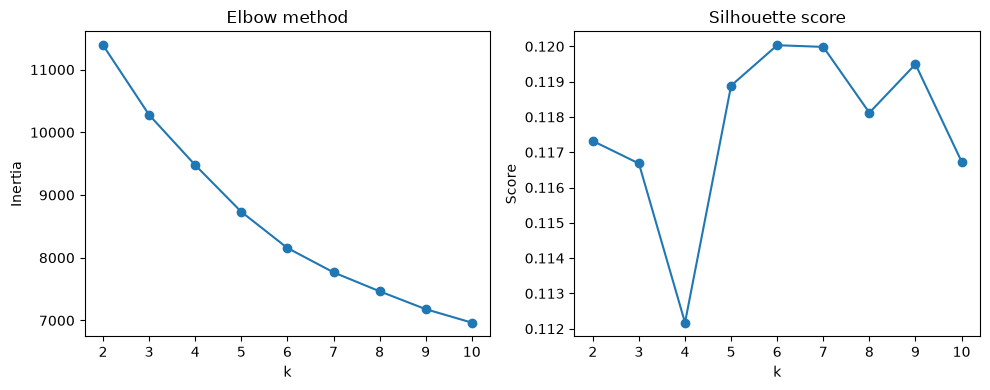

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(results["k"], results["inertia"], marker="o")
axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(results["k"], results["silhouette"], marker="o")
axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()

In [33]:
subsets = {
    "All features (20 cols)": X,
    "Numeric only (5 cols)": X_num,
    "Purchase behaviour only (3 cols)": X_num[["units_capped", "avg_price", "office_share"]],
}

rows = []
for name, M in subsets.items():
    for k in range(2, 9):
        labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(M)
        rows.append({"features": name, "k": k, "silhouette": silhouette_score(M, labels)})

compare = pd.DataFrame(rows).pivot(index="k", columns="features", values="silhouette").round(3)
compare

features,All features (20 cols),Numeric only (5 cols),Purchase behaviour only (3 cols)
k,,,
2,0.117,0.176,0.319
3,0.117,0.163,0.350
4,0.112,0.173,0.333
5,0.119,0.173,0.336
6,0.120,0.173,0.371
7,0.120,0.180,0.409
8,0.118,0.176,0.435


In [34]:
X_beh = X_num[["units_capped", "avg_price", "office_share"]]

res = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_beh)
    sizes = pd.Series(labels).value_counts()
    res.append({"k": k, "inertia": km.inertia_,
                "silhouette": silhouette_score(X_beh, labels),
                "smallest_cluster": sizes.min(), "largest_cluster": sizes.max()})

res = pd.DataFrame(res)
res.round(3)

,k,inertia,silhouette,smallest_cluster,largest_cluster
0,2,4379.064,0.319,895,1105
1,3,3435.206,0.350,118,1052
2,4,2624.110,0.333,119,727
3,5,2219.259,0.336,51,691
4,6,1801.216,0.371,51,505
5,7,1515.119,0.409,51,421
6,8,1334.807,0.435,51,431
7,9,1159.695,0.449,51,328
8,10,1025.353,0.462,51,328


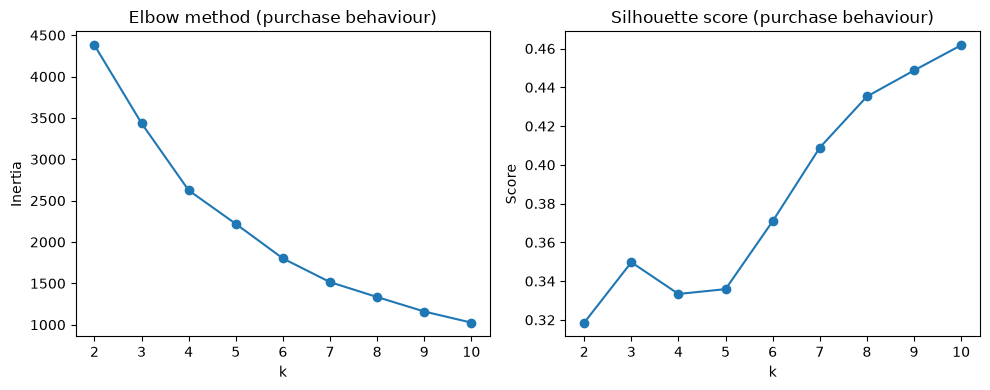

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(res["k"], res["inertia"], marker="o")
axes[0].set_title("Elbow method (purchase behaviour)"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(res["k"], res["silhouette"], marker="o")
axes[1].set_title("Silhouette score (purchase behaviour)"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()

In [36]:
k = 4   # change this number later to try other values
km = KMeans(n_clusters=k, n_init=10, random_state=42)
data["cluster"] = km.fit_predict(X_beh)

data.groupby("cluster").agg(
    clients=("client_id", "count"),
    units=("units_capped", "mean"),
    avg_price=("avg_price", "mean"),
    office_share=("office_share", "mean")
).round(2)

,clients,units,avg_price,office_share
cluster,,,,
0,727,3.51,309420.68,0.00
1,683,3.58,328250.72,0.35
2,471,3.39,438145.17,0.09
3,119,5.72,324953.42,0.14


In [37]:
for col in ["acquisition_purpose", "client_type", "loan_applied", "referral_channel", "gender", "country"]:
    print((pd.crosstab(data["cluster"], data[col], normalize="index") * 100).round(1))
    print()

acquisition_purpose  Home  Investment
cluster                              
0                    69.5        30.5
1                    68.1        31.9
2                    70.3        29.7
3                    70.6        29.4

client_type  Company  Individual
cluster                         
0                5.1        94.9
1                5.3        94.7
2                5.3        94.7
3                4.2        95.8

loan_applied    No   Yes
cluster                 
0             64.8  35.2
1             62.7  37.3
2             61.6  38.4
3             63.0  37.0

referral_channel  Agency  Client  Website
cluster                                  
0                   33.4     9.8     56.8
1                   37.6    10.2     52.1
2                   36.3     8.5     55.2
3                   28.6     9.2     62.2

gender      F     M
cluster            
0        51.3  48.7
1        49.6  50.4
2        47.3  52.7
3        44.5  55.5

country  Australia  Belgium  Canada  Denmark  F

In [38]:
data.groupby("cluster")[["age", "satisfaction_score"]].mean().round(2)

,age,satisfaction_score
cluster,,
0,53.11,3.07
1,54.23,2.94
2,53.48,2.99
3,61.83,3.46


In [39]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

hc = AgglomerativeClustering(n_clusters=4, linkage="ward")
data["hc_cluster"] = hc.fit_predict(X_beh)

print("silhouette (hierarchical):", round(silhouette_score(X_beh, data["hc_cluster"]), 3))
print("agreement with K-Means (adjusted Rand):", round(adjusted_rand_score(data["cluster"], data["hc_cluster"]), 3))
pd.crosstab(data["cluster"], data["hc_cluster"])

silhouette (hierarchical): 0.31
agreement with K-Means (adjusted Rand): 0.246


hc_cluster,0,1,2,3
cluster,,,,
0,364,0,363,0
1,0,382,301,0
2,325,85,61,0
3,0,0,72,47


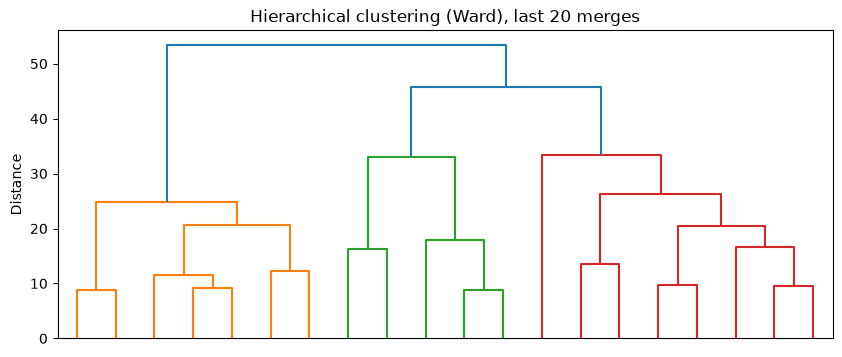

In [40]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_beh, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=20, no_labels=True)
plt.title("Hierarchical clustering (Ward), last 20 merges")
plt.ylabel("Distance")
plt.show()

In [41]:
from scipy.stats import chi2_contingency, f_oneway

rows = []
for col in ["acquisition_purpose", "client_type", "loan_applied", "referral_channel", "gender", "country"]:
    chi2, p, dof, expected = chi2_contingency(pd.crosstab(data["cluster"], data[col]))
    rows.append({"variable": col, "test": "chi-square", "p_value": round(p, 4)})

for col in ["age", "satisfaction_score"]:
    groups = [g[col].values for _, g in data.groupby("cluster")]
    f, p = f_oneway(*groups)
    rows.append({"variable": col, "test": "ANOVA", "p_value": round(p, 4)})

pd.DataFrame(rows)

,variable,test,p_value
0,acquisition_purpose,chi-square,0.8528
1,client_type,chi-square,0.9657
2,loan_applied,chi-square,0.7032
3,referral_channel,chi-square,0.3264
4,gender,chi-square,0.3927
5,country,chi-square,0.2284
6,age,ANOVA,0.0000
7,satisfaction_score,ANOVA,0.0021


In [42]:
data.to_csv("buyers_clustered.csv", index=False)
data["cluster"].value_counts().sort_index()

cluster
0    727
1    683
2    471
3    119
Name: count, dtype: int64

In [43]:
names = {0: "Apartment Buyers", 1: "Mixed-Use Buyers", 2: "Premium Buyers", 3: "Multi-Unit Buyers"}
data["segment"] = data["cluster"].map(names)
data.to_csv("buyers_clustered.csv", index=False)
data["segment"].value_counts()

segment
Apartment Buyers     727
Mixed-Use Buyers     683
Premium Buyers       471
Multi-Unit Buyers    119
Name: count, dtype: int64